--- Genome Codon Analysis ---
DNA   | RNA   | Amino Acid           | Frequency
-------------------------------------------------------
ATT   | AUU   | Isoleucine           | 338
TTT   | UUU   | Phenylalanine        | 317
TTG   | UUG   | Leucine              | 263
TAT   | UAU   | Tyrosine             | 261
TTA   | UUA   | Leucine              | 248
AAT   | AAU   | Asparagine           | 246
AAA   | AAA   | Lysine               | 224
ATG   | AUG   | Methionine (Start)   | 217
TGA   | UGA   | Stop                 | 217
AGT   | AGU   | Serine               | 203


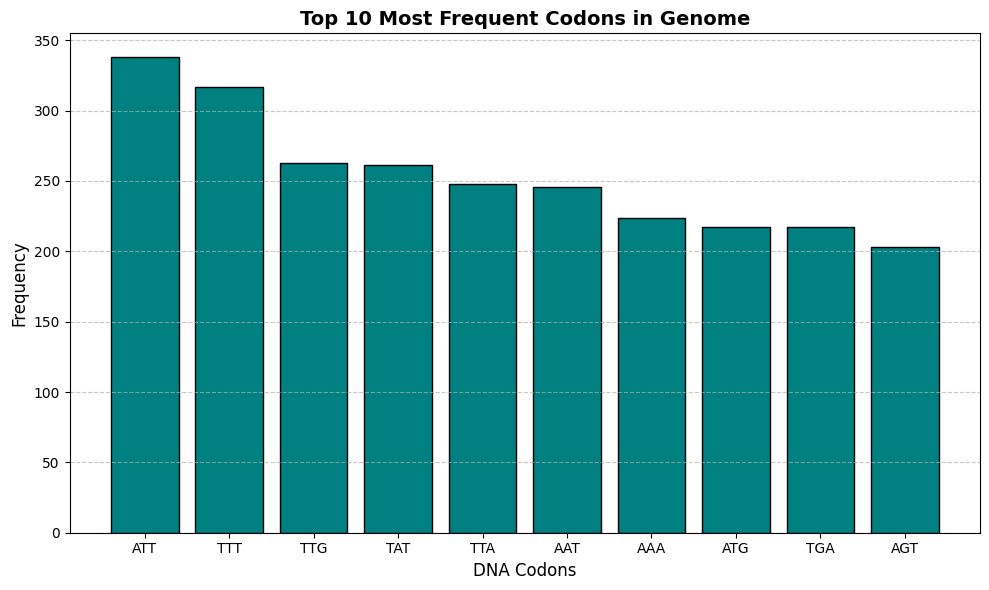

In [7]:

import sys
from collections import Counter
import matplotlib.pyplot as plt

# Standard RNA Codon Table
CODON_TABLE = {
    'UUU': 'Phenylalanine', 'UUC': 'Phenylalanine', 'UUA': 'Leucine', 'UUG': 'Leucine',
    'CUU': 'Leucine', 'CUC': 'Leucine', 'CUA': 'Leucine', 'CUG': 'Leucine',
    'AUU': 'Isoleucine', 'AUC': 'Isoleucine', 'AUA': 'Isoleucine', 'AUG': 'Methionine (Start)',
    'GUU': 'Valine', 'GUC': 'Valine', 'GUA': 'Valine', 'GUG': 'Valine',
    'UCU': 'Serine', 'UCC': 'Serine', 'UCA': 'Serine', 'UCG': 'Serine',
    'CCU': 'Proline', 'CCC': 'Proline', 'CCA': 'Proline', 'CCG': 'Proline',
    'ACU': 'Threonine', 'ACC': 'Threonine', 'ACA': 'Threonine', 'ACG': 'Threonine',
    'GCU': 'Alanine', 'GCC': 'Alanine', 'GCA': 'Alanine', 'GCG': 'Alanine',
    'UAU': 'Tyrosine', 'UAC': 'Tyrosine', 'UAA': 'Stop', 'UAG': 'Stop',
    'CAU': 'Histidine', 'CAC': 'Histidine', 'CAA': 'Glutamine', 'CAG': 'Glutamine',
    'AAU': 'Asparagine', 'AAC': 'Asparagine', 'AAA': 'Lysine', 'AAG': 'Lysine',
    'GAU': 'Aspartic Acid', 'GAC': 'Aspartic Acid', 'GAA': 'Glutamic Acid', 'GAG': 'Glutamic Acid',
    'UGU': 'Cysteine', 'UGC': 'Cysteine', 'UGA': 'Stop', 'UGG': 'Tryptophan',
    'CGU': 'Arginine', 'CGC': 'Arginine', 'CGA': 'Arginine', 'CGG': 'Arginine',
    'AGU': 'Serine', 'AGC': 'Serine', 'AGA': 'Arginine', 'AGG': 'Arginine',
    'GGU': 'Glycine', 'GGC': 'Glycine', 'GGA': 'Glycine', 'GGG': 'Glycine'
}

def read_fasta(file_path):
    sequence = []
    try:
        with open(file_path, 'r') as f:
            for line in f:
                line = line.strip()
                if not line.startswith('>'):  # Ignore header lines
                    sequence.append(line)
        return "".join(sequence).upper()
    except FileNotFoundError:
        print(f"Error: File '{file_path}' not found.")
        sys.exit(1)

def analyze_codons_and_plot(sequence, top_n=10):
    codons = []

    for i in range(len(sequence) - 2):
        codon = sequence[i:i+3]
        if all(base in 'ACGT' for base in codon):
            codons.append(codon)

    counter = Counter(codons)
    top_codons = counter.most_common(top_n)

    print(f"{'DNA':<5} | {'RNA':<5} | {'Amino Acid':<20} | {'Frequency'}")
    print("-" * 55)

    top_amino_acids = set()
    plot_labels = []
    plot_counts = []

    for dna_codon, count in top_codons:
        rna_codon = dna_codon.replace('T', 'U')
        amino_acid = CODON_TABLE.get(rna_codon, "Unknown")

        if amino_acid != "Stop":
            clean_name = amino_acid.replace(' (Start)', '')
            top_amino_acids.add(clean_name)

        print(f"{dna_codon:<5} | {rna_codon:<5} | {amino_acid:<20} | {count}")
        plot_labels.append(dna_codon)
        plot_counts.append(count)

    plt.figure(figsize=(10, 6))
    plt.bar(plot_labels, plot_counts, color='teal', edgecolor='black')

    plt.title(f"Top {top_n} Most Frequent Codons in Genome", fontsize=14, fontweight='bold')
    plt.xlabel("DNA Codons", fontsize=12)
    plt.ylabel("Frequency", fontsize=12)
    plt.grid(axis='y', linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.show()

    return top_amino_acids

if __name__ == "__main__":
    fasta_file = "virus.fna"

    print("--- Genome Codon Analysis ---")
    seq = read_fasta(fasta_file)
    top_aa = analyze_codons_and_plot(seq, 10)
